In [1]:
!pip install -q datasets scikit-fuzzy scikit-learn pandas numpy matplotlib seaborn

In [2]:
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import skfuzzy as fuzz
from skfuzzy import control as ctrl

from datasets import load_dataset

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

random.seed(42)
np.random.seed(42)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
dataset = load_dataset(
    "Algo0o/flight_delay",
    split="train",
    streaming=True
)

rows = list(dataset.take(100000))

df = pd.DataFrame(rows)

print("Dataset Shape:", df.shape)

display(df.head())

README.md:   0%|          | 0.00/6.93k [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


Dataset Shape: (100000, 49)


,airline_id,FL_DATE,OP_UNIQUE_CARRIER,OP_CARRIER_FL_NUM,ORIGIN_AIRPORT_ID,ORIGIN,ORIGIN_CITY_NAME,ORIGIN_STATE_ABR,ORIGIN_STATE_FIPS,ORIGIN_STATE_NM,...,DISTANCE_GROUP,CARRIER_DELAY,WEATHER_DELAY,NAS_DELAY,SECURITY_DELAY,LATE_AIRCRAFT_DELAY,DEP_DELAY_OVER15,ARR_DELAY_OVER15,TOTAL_DELAY,ANY_DELAY
0,1,2025-07-01,AA,1,12478,JFK,New York,NY,36,New York,...,10,0.0,0.0,0.0,0.0,0.0,0,0,0.0,0
1,2,2025-07-01,UA,2621,12266,IAH,Houston,TX,48,Texas,...,1,0.0,0.0,0.0,0.0,0.0,0,0,0.0,0
2,3,2025-07-01,UA,2621,11278,DCA,Washington,VA,51,Virginia,...,5,0.0,21.0,0.0,0.0,9.0,1,1,30.0,1
3,4,2025-07-01,UA,2620,13486,MSO,Missoula,MT,30,Montana,...,6,0.0,0.0,29.0,0.0,0.0,0,1,29.0,1
4,5,2025-07-01,UA,2619,11292,DEN,Denver,CO,8,Colorado,...,4,0.0,0.0,0.0,0.0,0.0,0,0,0.0,0


In [4]:
data = df[
    ["CRS_DEP_TIME", "DISTANCE", "FL_DATE", "DEP_DEL15"]
].copy()

data["CRS_DEP_TIME"] = pd.to_numeric(
    data["CRS_DEP_TIME"], errors="coerce"
)

data["DISTANCE"] = pd.to_numeric(
    data["DISTANCE"], errors="coerce"
)

dates = pd.to_datetime(data["FL_DATE"], errors="coerce")

data["DEP_HOUR"] = data["CRS_DEP_TIME"] // 100
data["DAY_OF_WEEK"] = dates.dt.dayofweek + 1
data["MONTH"] = dates.dt.month

data = data[
    ["DEP_HOUR", "DISTANCE", "DAY_OF_WEEK", "MONTH", "DEP_DEL15"]
]

data = data.apply(pd.to_numeric, errors="coerce")
data = data.dropna()

data = data[
    data["DEP_HOUR"].between(0, 23) &
    (data["DISTANCE"] > 0) &
    data["DAY_OF_WEEK"].between(1, 7) &
    data["MONTH"].between(1, 12) &
    data["DEP_DEL15"].isin([0, 1])
]

data["DEP_DEL15"] = data["DEP_DEL15"].astype(int)

data = data.reset_index(drop=True)

print("Cleaned Dataset:", data.shape)

display(data.head())

Cleaned Dataset: (98236, 5)


,DEP_HOUR,DISTANCE,DAY_OF_WEEK,MONTH,DEP_DEL15
0,7,2475,2,7,0
1,20,140,2,7,0
2,16,1208,2,7,1
3,12,1332,2,7,0
4,13,846,2,7,0


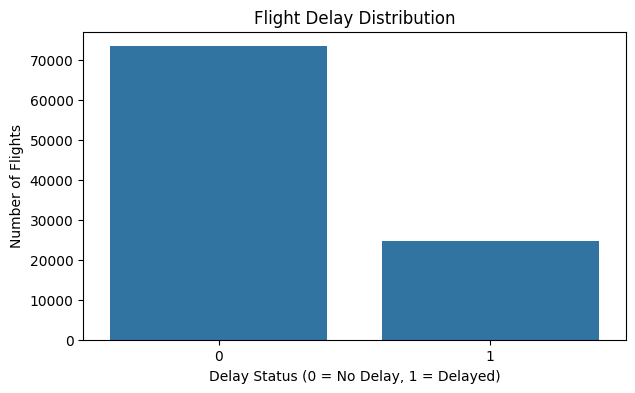

DEP_DEL15
0    73458
1    24778
Name: count, dtype: int64


In [5]:
plt.figure(figsize=(7, 4))

sns.countplot(
    data=data,
    x="DEP_DEL15"
)

plt.title("Flight Delay Distribution")
plt.xlabel("Delay Status (0 = No Delay, 1 = Delayed)")
plt.ylabel("Number of Flights")

plt.show()

print(data["DEP_DEL15"].value_counts())

In [6]:
features = [
    "DEP_HOUR",
    "DISTANCE",
    "DAY_OF_WEEK",
    "MONTH"
]

X = data[features]
y = data["DEP_DEL15"]

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

scaler = MinMaxScaler(feature_range=(0, 10))

X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 78588
Testing Samples: 19648


In [7]:
def build_fuzzy_system(boundary=5):

    hour = ctrl.Antecedent(
        np.arange(0, 10.1, 0.1), "hour"
    )

    distance = ctrl.Antecedent(
        np.arange(0, 10.1, 0.1), "distance"
    )

    weekday = ctrl.Antecedent(
        np.arange(0, 10.1, 0.1), "weekday"
    )

    month = ctrl.Antecedent(
        np.arange(0, 10.1, 0.1), "month"
    )

    risk = ctrl.Consequent(
        np.arange(0, 101, 1), "risk"
    )

    variables = [hour, distance, weekday, month]

    for v in variables:

        v["low"] = fuzz.trimf(
            v.universe, [0, 0, boundary]
        )

        v["medium"] = fuzz.trimf(
            v.universe, [0, boundary, 10]
        )

        v["high"] = fuzz.trimf(
            v.universe, [boundary, 10, 10]
        )

    risk["low"] = fuzz.trimf(
        risk.universe, [0, 0, 50]
    )

    risk["high"] = fuzz.trimf(
        risk.universe, [50, 100, 100]
    )

    rules = [

        ctrl.Rule(hour["high"] & distance["high"], risk["high"]),

        ctrl.Rule(hour["high"] & weekday["high"], risk["high"]),

        ctrl.Rule(distance["high"] & month["high"], risk["high"]),

        ctrl.Rule(weekday["high"] & month["high"], risk["high"]),

        ctrl.Rule(hour["low"] & distance["low"], risk["low"]),

        ctrl.Rule(hour["low"] & weekday["low"], risk["low"]),

        ctrl.Rule(distance["low"] & month["low"], risk["low"]),

        ctrl.Rule(weekday["low"] & month["low"], risk["low"]),

        ctrl.Rule(hour["medium"] & distance["medium"], risk["low"]),

        ctrl.Rule(weekday["medium"] & month["medium"], risk["low"]),

        ctrl.Rule(hour["high"] & distance["low"], risk["low"]),

        ctrl.Rule(hour["low"] & distance["high"], risk["high"])
    ]

    return ctrl.ControlSystem(rules)


fuzzy_system = build_fuzzy_system()

print("Fuzzy Logic system created successfully!")

Fuzzy Logic system created successfully!


In [8]:
def fuzzy_predict(X_values, system):

    scores = []
    fallback_count = 0

    for row in X_values:

        simulation = ctrl.ControlSystemSimulation(system)

        simulation.input["hour"] = float(row[0])
        simulation.input["distance"] = float(row[1])
        simulation.input["weekday"] = float(row[2])
        simulation.input["month"] = float(row[3])

        try:

            simulation.compute()

            score = simulation.output["risk"]

            if not np.isfinite(score):
                score = 50
                fallback_count += 1

        except (ValueError, KeyError):

            score = 50
            fallback_count += 1

        scores.append(score)

    return np.array(scores), fallback_count

In [9]:
# Select stratified test sample
eval_n = min(500, len(X_test))

eval_indices, _ = train_test_split(
    np.arange(len(X_test)),
    train_size=eval_n,
    stratify=y_test,
    random_state=42
)

X_eval = X_test[eval_indices]

y_eval = y_test.iloc[eval_indices].reset_index(drop=True)

# Baseline predictions
fuzzy_scores, fallback_count = fuzzy_predict(
    X_eval, fuzzy_system
)

fuzzy_predictions = (
    fuzzy_scores >= 50
).astype(int)

print("Fallback cases:", fallback_count)

print(classification_report(
    y_eval,
    fuzzy_predictions,
    zero_division=0
))

Fallback cases: 0
              precision    recall  f1-score   support

           0       0.75      0.98      0.85       374
           1       0.40      0.03      0.06       126

    accuracy                           0.74       500
   macro avg       0.58      0.51      0.46       500
weighted avg       0.66      0.74      0.65       500



In [10]:
X_train_part, X_val, y_train_part, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=42
)

ga_n = min(250, len(X_val))

ga_indices, _ = train_test_split(
    np.arange(len(X_val)),
    train_size=ga_n,
    stratify=y_val,
    random_state=42
)

X_ga = X_val[ga_indices]
y_ga = y_val.iloc[ga_indices].to_numpy()

print("GA validation samples:", len(X_ga))

GA validation samples: 250


In [11]:
def fitness_function(chromosome):

    boundary, threshold = chromosome

    system = build_fuzzy_system(boundary)

    scores, _ = fuzzy_predict(X_ga, system)

    predictions = (
        scores >= threshold
    ).astype(int)

    return f1_score(
        y_ga,
        predictions,
        zero_division=0
    )


POPULATION_SIZE = 8
GENERATIONS = 5

population = [
    [
        random.uniform(3.5, 6.5),
        random.uniform(30, 65)
    ]
    for _ in range(POPULATION_SIZE)
]

best_solution = None
best_fitness = -1

ga_history = []

for generation in range(GENERATIONS):

    fitness_values = [
        fitness_function(ind)
        for ind in population
    ]

    ranked = sorted(
        zip(fitness_values, population),
        key=lambda x: x[0],
        reverse=True
    )

    if ranked[0][0] > best_fitness:

        best_fitness = ranked[0][0]
        best_solution = ranked[0][1].copy()

    ga_history.append(best_fitness)

    print(
        f"Generation {generation + 1}: "
        f"Best F1 = {best_fitness:.4f}"
    )

    parents = [
        item[1] for item in ranked[:4]
    ]

    new_population = parents[:2]

    while len(new_population) < POPULATION_SIZE:

        p1, p2 = random.sample(parents, 2)

        boundary = (p1[0] + p2[0]) / 2
        threshold = (p1[1] + p2[1]) / 2

        boundary += random.uniform(-0.25, 0.25)
        threshold += random.uniform(-2.5, 2.5)

        boundary = np.clip(boundary, 3.5, 6.5)
        threshold = np.clip(threshold, 30, 65)

        new_population.append([
            float(boundary),
            float(threshold)
        ])

    population = new_population


best_boundary, best_threshold = best_solution

print("\nOptimized Boundary:", best_boundary)
print("Optimized Threshold:", best_threshold)
print("Best Validation F1:", best_fitness)

Generation 1: Best F1 = 0.2419
Generation 2: Best F1 = 0.2419
Generation 3: Best F1 = 0.2500
Generation 4: Best F1 = 0.2540
Generation 5: Best F1 = 0.2540

Optimized Boundary: 3.7227317243329616
Optimized Threshold: 35.406060927486536
Best Validation F1: 0.25396825396825395


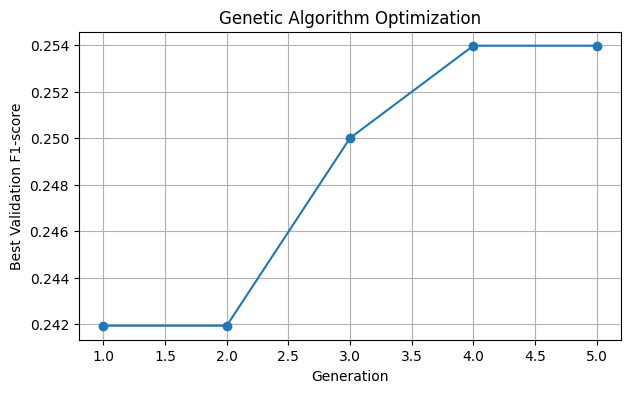

In [12]:
plt.figure(figsize=(7, 4))

plt.plot(
    range(1, GENERATIONS + 1),
    ga_history,
    marker="o"
)

plt.title("Genetic Algorithm Optimization")
plt.xlabel("Generation")
plt.ylabel("Best Validation F1-score")

plt.grid()
plt.show()

In [13]:
ga_system = build_fuzzy_system(best_boundary)

ga_scores, ga_fallbacks = fuzzy_predict(
    X_eval,
    ga_system
)

ga_predictions = (
    ga_scores >= best_threshold
).astype(int)

print("GA fallback cases:", ga_fallbacks)

print(classification_report(
    y_eval,
    ga_predictions,
    zero_division=0
))

GA fallback cases: 0
              precision    recall  f1-score   support

           0       0.78      0.82      0.80       374
           1       0.36      0.30      0.33       126

    accuracy                           0.69       500
   macro avg       0.57      0.56      0.56       500
weighted avg       0.67      0.69      0.68       500



In [14]:
comparison = pd.DataFrame({

    "Model": [
        "Fuzzy Logic",
        "GA-Tuned Fuzzy Logic"
    ],

    "Accuracy": [
        accuracy_score(y_eval, fuzzy_predictions),
        accuracy_score(y_eval, ga_predictions)
    ],

    "Precision": [
        precision_score(y_eval, fuzzy_predictions, zero_division=0),
        precision_score(y_eval, ga_predictions, zero_division=0)
    ],

    "Recall": [
        recall_score(y_eval, fuzzy_predictions, zero_division=0),
        recall_score(y_eval, ga_predictions, zero_division=0)
    ],

    "F1-score": [
        f1_score(y_eval, fuzzy_predictions, zero_division=0),
        f1_score(y_eval, ga_predictions, zero_division=0)
    ]

})

display(comparison.round(4))

,Model,Accuracy,Precision,Recall,F1-score
0,Fuzzy Logic,0.744,0.4000,0.0317,0.0588
1,GA-Tuned Fuzzy Logic,0.686,0.3551,0.3016,0.3262


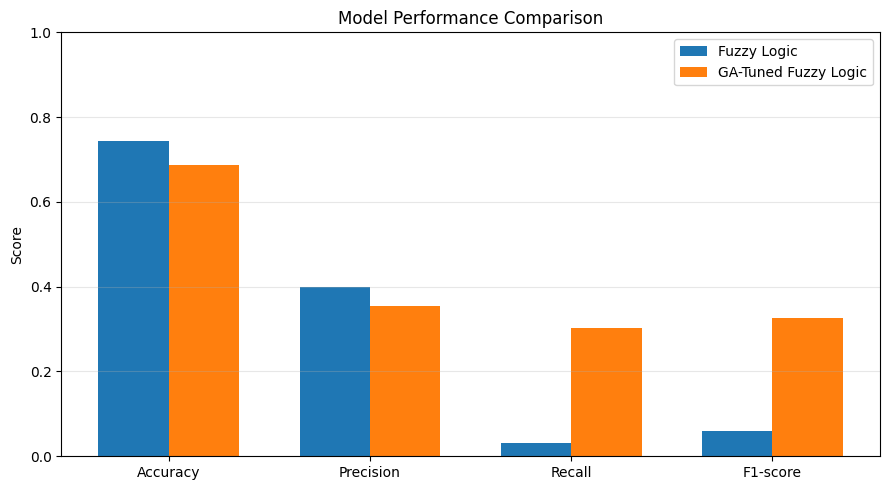

In [15]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score"
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width/2,
    comparison.iloc[0][metrics],
    width,
    label="Fuzzy Logic"
)

plt.bar(
    x + width/2,
    comparison.iloc[1][metrics],
    width,
    label="GA-Tuned Fuzzy Logic"
)

plt.xticks(x, metrics)
plt.ylabel("Score")

plt.title("Model Performance Comparison")

plt.ylim(0, 1)

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig("model_comparison.png", dpi=300)

plt.show()

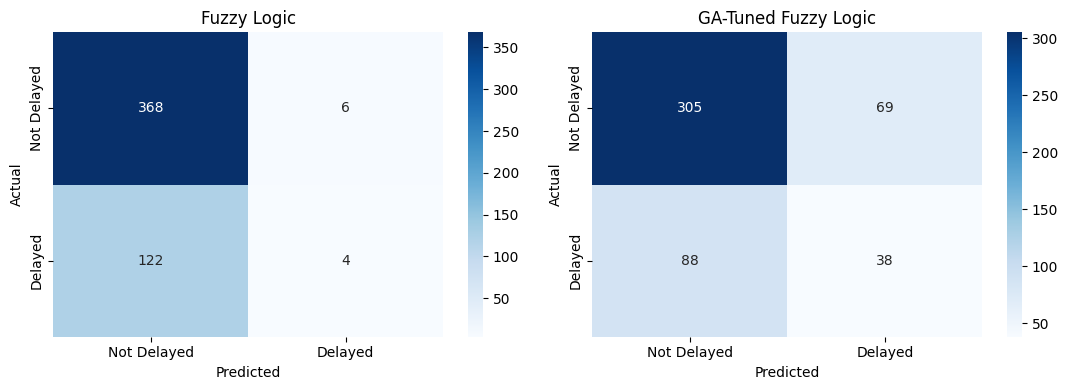

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

models = [
    (fuzzy_predictions, "Fuzzy Logic"),
    (ga_predictions, "GA-Tuned Fuzzy Logic")
]

for ax, (predictions, name) in zip(axes, models):

    cm = confusion_matrix(y_eval, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        xticklabels=["Not Delayed", "Delayed"],
        yticklabels=["Not Delayed", "Delayed"]
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()

plt.savefig("confusion_matrix.png", dpi=300)

plt.show()

In [17]:
sample_flight = pd.DataFrame({

    "DEP_HOUR": [18],
    "DISTANCE": [900],
    "DAY_OF_WEEK": [2],
    "MONTH": [7]

})

sample_scaled = scaler.transform(
    sample_flight[features]
)

sample_score, _ = fuzzy_predict(
    sample_scaled,
    ga_system
)

score = sample_score[0]

print("Flight Risk Score:", round(score, 2))

if score >= best_threshold:
    print("Prediction: Likely Delayed")
else:
    print("Prediction: Likely Not Delayed")

Flight Risk Score: 16.67
Prediction: Likely Not Delayed
